# 클래스 분포 확인 및 층화 분할

- **작성자**: 최원우
- **데이터**: `data/steel_plates_faults_processed1.csv`
- **실행 방법**: 저장소 최상위에서 위에서부터 순서대로 실행(Run All)

## 0. 데이터 불러오기

전처리 결과 파일(`processed1`)을 읽는다. 저장할 때 `utf-8-sig`로 저장했으므로 읽을 때도 같은 인코딩을 지정한다.

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split

df = pd.read_csv("data/steel_plates_faults_processed1.csv", encoding="utf-8-sig")
X = df.drop(columns="Fault")
y = df["Fault"]

## 1. 클래스 분포 확인

타깃 건수만 세는 분석이라 Test 정보가 모델 설계에 섞이지 않으므로 **전체 데이터**로 확인한다. 이 불균형이 다음 절에서 층화 분할을 쓰는 근거가 된다.

              count  ratio(%)
Fault                        
Other_Faults    673     34.67
Bumps           402     20.71
K_Scatch        391     20.14
Z_Scratch       190      9.79
Pastry          158      8.14
Stains           72      3.71
Dirtiness        55      2.83

불균형 비율(최다/최소): 673 / 55 = 12.2배


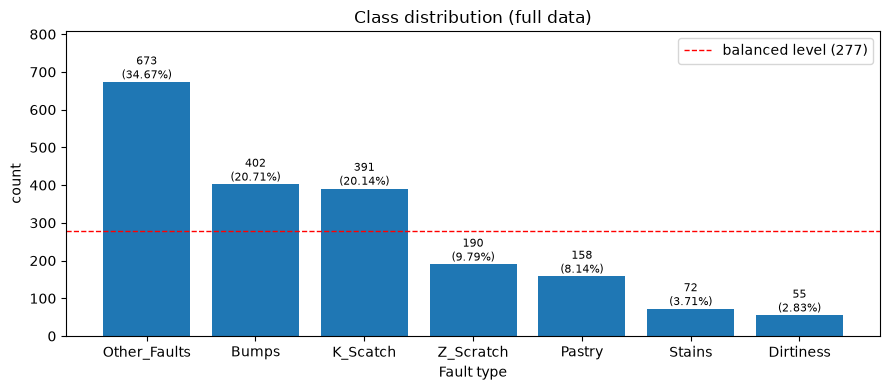

In [2]:
dist = pd.DataFrame({
    "count": y.value_counts(),
    "ratio(%)": (y.value_counts(normalize=True) * 100).round(2),
})
print(dist)
print(f"\n불균형 비율(최다/최소): {dist['count'].max()} / {dist['count'].min()}"
      f" = {dist['count'].max() / dist['count'].min():.1f}배")

fig, ax = plt.subplots(figsize=(9, 4))
bars = ax.bar(dist.index, dist["count"], color="tab:blue")
ax.axhline(len(y) / y.nunique(), color="r", ls="--", lw=1,
           label=f"balanced level ({len(y) / y.nunique():.0f})")
for bar, (cnt, pct) in zip(bars, dist.values):
    ax.text(bar.get_x() + bar.get_width() / 2, cnt, f"{int(cnt)}\n({pct}%)",
            ha="center", va="bottom", fontsize=8)
ax.set_title("Class distribution (full data)")
ax.set_xlabel("Fault type"); ax.set_ylabel("count")
ax.set_ylim(0, dist["count"].max() * 1.2)
ax.legend()
plt.tight_layout()
plt.show()

## 2. 파일 행 순서 확인 (shuffle이 필요한 근거)

원본 파일의 행이 클래스별로 묶여 정렬되어 있는지 확인한다. 정렬되어 있다면 섞지 않고 앞뒤로 자를 때 Test가 특정 클래스로만 채워진다.

          Fault  start_row  end_row    n
0        Pastry          0      157  158
1     Z_Scratch        158      347  190
2      K_Scatch        348      738  391
3        Stains        739      810   72
4     Dirtiness        811      865   55
5         Bumps        866     1267  402
6  Other_Faults       1268     1940  673

연속 블록 수: 7개 / 클래스 수: 7개 → 같으면 클래스마다 한 덩어리로 정렬된 것

Test(389행) 클래스 구성
               shuffle=False  stratified
Fault                                  
Other_Faults            389         135
Bumps                     0          81
K_Scatch                  0          78
Z_Scratch                 0          38
Pastry                    0          32
Stains                    0          14
Dirtiness                 0          11


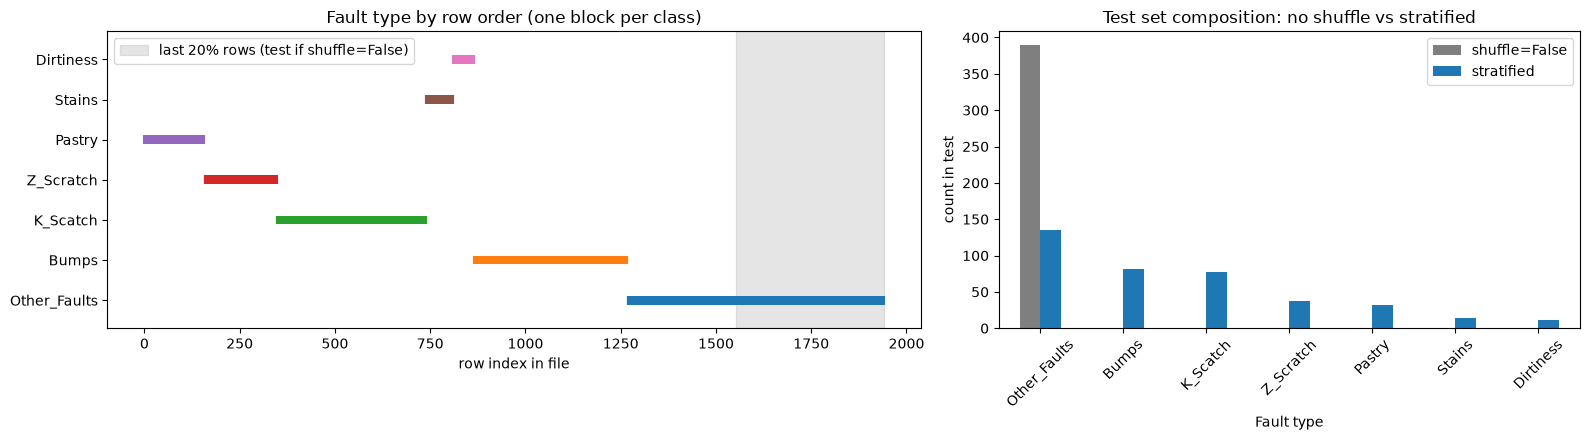

In [3]:
# (1) 클래스가 바뀌는 지점을 찾아 연속 블록으로 묶기
order = y.reset_index(drop=True)
block_id = (order != order.shift()).cumsum()          # 클래스가 바뀔 때마다 +1
blocks = pd.DataFrame({
    "Fault": order.groupby(block_id).first(),
    "start_row": order.index.to_series().groupby(block_id).min(),
    "end_row": order.index.to_series().groupby(block_id).max(),
    "n": order.groupby(block_id).size(),
}).reset_index(drop=True)
print(blocks)
print(f"\n연속 블록 수: {len(blocks)}개 / 클래스 수: {order.nunique()}개"
      " → 같으면 클래스마다 한 덩어리로 정렬된 것")

# (2) 섞지 않고 자른 경우 vs 층화 분할한 경우의 Test 클래스 구성
_, _, _, y_test_noshuf = train_test_split(X, y, test_size=0.2, shuffle=False)
_, _, _, y_test_strat = train_test_split(X, y, test_size=0.2, stratify=y, random_state=42)
compare = pd.concat(
    [y_test_noshuf.value_counts(), y_test_strat.value_counts()],
    axis=1, keys=["shuffle=False", "stratified"],
).reindex(dist.index).fillna(0).astype(int)
print("\nTest(389행) 클래스 구성\n", compare)

# (3) 시각화
classes = dist.index.tolist()
colors = dict(zip(classes, plt.cm.tab10.colors))
fig, axes = plt.subplots(1, 2, figsize=(16, 4.5), gridspec_kw={"width_ratios": [1.4, 1]})

ax = axes[0]
codes = order.map({c: i for i, c in enumerate(classes)})
ax.scatter(order.index, codes, c=order.map(colors).tolist(), s=40, marker="|", zorder=2)
ax.set_ylim(-0.7, len(classes) - 0.3)
ax.set_yticks(range(len(classes)), classes)
ax.axvspan(len(y) - len(y_test_noshuf), len(y), color="gray", alpha=0.2, zorder=0,
           label="last 20% rows (test if shuffle=False)")
ax.set_xlabel("row index in file"); ax.set_title("Fault type by row order (one block per class)")
ax.legend(loc="upper left")

compare.plot(kind="bar", ax=axes[1], color=["tab:gray", "tab:blue"])
axes[1].set_title("Test set composition: no shuffle vs stratified")
axes[1].set_xlabel("Fault type"); axes[1].set_ylabel("count in test")
axes[1].tick_params(axis="x", rotation=45)
plt.tight_layout()
plt.show()

## 3. 층화 분할 (Train 80% / Test 20%)

- `stratify=y`: Train·Test의 클래스 비율을 전체와 같게 유지
- `random_state=42`: 팀원 모두 같은 분할을 재현
- 2절에서 확인했듯 파일이 클래스 순서로 정렬되어 있으므로 `shuffle=True`(기본값)가 반드시 필요

이후 클래스와 변수의 관계 분석은 **Train으로만** 진행한다.

In [4]:
# 파일이 클래스 순서로 정렬되어 있으므로 shuffle(기본값 True)이 반드시 필요
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=42
)
print("train:", X_train.shape, "/ test:", X_test.shape)

train: (1552, 26) / test: (389, 26)


## 4. 분할 결과 확인

전체·Train·Test의 클래스 비율이 같은지 비교해 층화가 제대로 되었는지 확인한다.

In [5]:
check = pd.concat(
    [y.value_counts(), y_train.value_counts(), y_test.value_counts(),
     (y.value_counts(normalize=True) * 100).round(2),
     (y_train.value_counts(normalize=True) * 100).round(2),
     (y_test.value_counts(normalize=True) * 100).round(2)],
    axis=1,
    keys=["all_n", "train_n", "test_n", "all_%", "train_%", "test_%"],
)
print(check)
print("\n비율 최대 차이(%p):",
      (check[["train_%", "test_%"]].sub(check["all_%"], axis=0)).abs().max().max().round(2))

              all_n  train_n  test_n  all_%  train_%  test_%
Fault                                                       
Other_Faults    673      538     135  34.67    34.66   34.70
Bumps           402      321      81  20.71    20.68   20.82
K_Scatch        391      313      78  20.14    20.17   20.05
Z_Scratch       190      152      38   9.79     9.79    9.77
Pastry          158      126      32   8.14     8.12    8.23
Stains           72       58      14   3.71     3.74    3.60
Dirtiness        55       44      11   2.83     2.84    2.83

비율 최대 차이(%p): 0.11


## 5. Test 인덱스 저장

팀원 모두 같은 Test를 쓰도록 `data/test_index.csv`로 저장해 공유한다.

In [6]:
pd.Series(X_test.index, name="test_index").to_csv("data/test_index.csv", index=False)

# 다른 노트북에서 같은 분할을 재현하는 방법:
# test_idx = pd.read_csv("data/test_index.csv")["test_index"]
# test  = df.loc[test_idx]
# train = df.drop(index=test_idx)